# Exposición al incumplimiento y factor de conversión de crédito: la trampa de la terminología

**Pregunta:** Cuando un documento habla del factor de conversión de crédito de una línea rotativa, ¿a cuál de tres razones distintas se refiere, y cuánto mueven el factor de una cartera generada, cuyo factor verdadero se conoce, la fecha de referencia y el tratamiento de los valores extremos?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 de este tema (la LGD de recuperación) y los notebooks 01 y 02 del tema 01
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- calcular la exposición al incumplimiento de una línea rotativa a partir de un factor de conversión de crédito, y volver de la EAD al factor;
- decir cuál de los tres números llamados "el CCF" quiere decir un documento: el factor europeo sobre el monto no utilizado, el equivalente de préstamo de EE.UU. y las razones de Qi (2009) al saldo y al límite;
- elegir y leer los tres diseños de fecha de referencia (horizonte fijo, cohorte, horizonte variable) con `reference_indices` y `ccf_observations`, y decir cuándo un factor no está definido;
- tratar un factor bajo 0 o sobre 1 de las cuatro formas de `treat_ccf`, y decir qué hace cada una a la media;
- leer la distribución de los factores del generador C09 y la regla del monto no utilizado pequeño.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Poner la cartera de código del caso en la ruta de importación, importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf, workout

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator, params

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos artefactos versionados del caso C09, la exposición al incumplimiento y el factor de conversión de líneas rotativas: `data/derived/C09/level-0.json` (la variante del nivel de aceleración 0) y `data/derived/C09/models-generator.json` (el generador y los diseños detrás de cada nivel). C09 tiene **una verdad conocida**. Sus líneas las produce un generador cuya estructura de campos y distribuciones marginales siguen las carteras hipotéticas de tarjetas de la Reserva Federal de 2025, y el generador sortea los saldos con un factor de conversión que es un parámetro propio. Por eso cada estimación se muestra junto a la verdad que debería recuperar, y los datos son sintéticos, no observaciones de ningún prestamista.

El nivel 0 significa sin aceleración: el monto no utilizado se gira a ritmo constante durante los doce meses previos al incumplimiento. Los notebooks 05 y 07 de este tema suben el nivel; aquí el nivel 0 enseña el vocabulario. Los artefactos guardan el plan de las replicaciones y la convención; las líneas mismas no se versionan, porque el generador las vuelve a sortear desde una semilla. El paso 4 sortea entonces una replicación en el notebook, con el generador propio del caso en `data-pipeline/pipeline/cases/c09` y la primera semilla de prueba del plan versionado: 50.000 facilidades, de las cuales unos pocos miles caen en incumplimiento. No se escribe nada en disco.

In [2]:
# Abrir los dos artefactos e imprimir la versión del motor, el aviso del generador y los tres diseños
derived = ROOT / "data" / "derived" / "C09"
level0 = json.loads((derived / "level-0.json").read_text(encoding="utf-8"))
gen = json.loads((derived / "models-generator.json").read_text(encoding="utf-8"))
out = level0["outputs"]
print("horneado con riskvalidation:", level0["provenance"]["riskvalidation_version"])
print("instalado:", rv.__version__)
print(out["generator"]["notice"]["es"])
print("convención:", out["convention"]["name"], "|", out["convention"]["formula"])
for design in gen["fit"]["designs"]:
    print("-", design["label"]["es"])

horneado con riskvalidation: 1.0.1
instalado: 1.0.1
Datos sintéticos: son líneas de crédito rotativas generadas, no observaciones de ninguna cartera ni evidencia sobre ningún banco o emisor de tarjetas. Su estructura de campos y sus marginales siguen las carteras hipotéticas de tarjetas de 2025 de la Reserva Federal; el CCF con que cada nivel simula los saldos es un parámetro del propio generador, de modo que cada estimación se muestra junto a la verdad que debe recuperar. Montos en USD.
convención: eu-undrawn | CCF = (EAD - E(t_r)) / (L(t_r) - E(t_r))
- Horizonte fijo: 12 meses antes del incumplimiento
- Cohorte anual: el inicio de la cohorte
- Horizonte variable: fechas trimestrales de referencia en el año previo al incumplimiento


## Método

### Paso 1: una línea, tres números

Una línea rotativa tiene un límite $L$ y un saldo utilizado $E$ en una fecha de referencia, y la exposición al incumplimiento del banco es la $EAD$. La investigación de este producto registra la convención europea como

$$CCF = \frac{EAD - E(t_r)}{L(t_r) - E(t_r)} \qquad\Longleftrightarrow\qquad EAD = E(t_r) + CCF\,\big(L(t_r) - E(t_r)\big)$$

con $t_r$ la fecha de referencia anterior a la fecha de incumplimiento $t_d$: la parte del monto no utilizado que se usa al incumplir. En términos de EE.UU. la misma razón es el equivalente de préstamo (LEQ). Qi (2009) usa las mismas palabras para otras razones: su "CCF" es $EAD / E$ (sobre el saldo) y su "EADF" es $EAD / L$ (sobre el límite). (Fuentes: el docstring de `riskvalidation.lgd_ead.ccf` en la versión 0.8.1, y Qi 2009, OCC Economics Working Paper 2009-2, como se nombra allí.) Un documento que dice "el CCF" sin nombrar el denominador puede querer decir cualquiera de los tres, y esta es la trampa de la terminología.

`to_us_terms(drawn, limit, ead)` devuelve los tres números de cada línea, y `ead_from_ccf(drawn, limit, ccf)` vuelve atrás. La celda siguiente inventa tres líneas: una parcialmente usada al incumplir, una totalmente usada y una sobre su límite.

In [3]:
# Tres facilidades inventadas: los tres números llamados CCF, y la EAD recuperada desde el factor europeo
names = ["parcial", "completa", "sobre el límite"]
drawn = np.array([60.0, 20.0, 90.0])
limit = np.array([100.0, 100.0, 100.0])
ead = np.array([85.0, 100.0, 120.0])

leq, ccf_us, eadf = ccf.to_us_terms(drawn, limit, ead)
print(f"{"":16s} {"E":>4s} {'L':>4s} {'EAD':>4s} | {'factor UE':>9s} | {'EAD/E':>7s} | {'EAD/L':>6s}")
for i, name in enumerate(names):
    head = f"{name:16s} {drawn[i]:4.0f} {limit[i]:4.0f} {ead[i]:4.0f}"
    print(f"{head} | {leq[i]:9.4f} | {ccf_us[i]:7.4f} | {eadf[i]:6.4f}")
print("EAD recuperada desde el factor europeo:", ccf.ead_from_ccf(drawn, limit, leq))

                    E    L  EAD | factor UE |   EAD/E |  EAD/L
parcial            60  100   85 |    0.6250 |  1.4167 | 0.8500
completa           20  100  100 |    1.0000 |  5.0000 | 1.0000
sobre el límite    90  100  120 |    3.0000 |  1.3333 | 1.2000
EAD recuperada desde el factor europeo: [ 85. 100. 120.]


La misma línea vale 0.625, 1.4167 y 0.85 según la razón. El factor europeo es exactamente 1 para la línea totalmente usada (usó todo su monto no utilizado) y 3 para la línea sobre su límite (el límite era 100, el saldo 90, y el banco terminó 30 sobre el saldo: tres veces los 10 que quedaban sin usar). Nótese lo que hace el factor cuando el monto no utilizado es pequeño: unas pocas unidades monetarias sin utilizar en el denominador hacen explotar la razón, y por eso el paso 5 vuelve sobre esto.

### Paso 2: ¿qué mes es la fecha de referencia?

El factor necesita una fecha de referencia $t_r$ anterior al incumplimiento, y la elección es un diseño del modelo, no un detalle. `reference_indices(design, default_index, ...)` del motor da los meses de la trayectoria de una línea para cada diseño:

- `fixed-horizon`: una fecha, `horizon` meses antes del incumplimiento (`t_d - h`);
- `cohort`: una fecha, el inicio de la cohorte calendario que contiene el incumplimiento (quien llama entrega `cohort_start_index`);
- `variable-horizon`: `n_reference` fechas, `t_d - h + k * step` para `k = 0 ... n_reference - 1`.

(Fuente: el docstring de `reference_indices`; los tres diseños siguen a Moral (2006) como los resume la investigación, y el motor marca el detalle NO VERIFICADO porque ese capítulo no se leyó.) Una fecha de referencia negativa o no anterior al incumplimiento produce un error. `ccf_observations(drawn, limit, ead, reference_index)` devuelve entonces el factor y el monto no utilizado en cada fecha, y `aggregate_ccf` los combina como la media de los factores o como la razón agrupada $\sum (CCF\,U) / \sum U$ de los montos no utilizados $U$.

La celda siguiente inventa la trayectoria mensual de una línea que cae en incumplimiento en el mes 20 con una EAD de 88, y de una segunda línea totalmente usada desde el mes 14. Imprime los meses que elige cada diseño y el factor que da cada uno.

In [4]:
# Dos trayectorias mensuales inventadas: los meses de referencia de cada diseño, los factores y sus dos agregaciones
limit_path = np.full(21, 100.0)
drawn_a = np.linspace(30.0, 85.0, 21)
drawn_b = np.minimum(np.linspace(40.0, 130.0, 21), 100.0)
default_month = 20
shown = {"fixed-horizon": "horizonte fijo", "cohort": "cohorte",
         "variable-horizon": "horizonte variable"}
designs = {"fixed-horizon": dict(horizon=12), "cohort": dict(cohort_start_index=12),
           "variable-horizon": dict(horizon=12, n_reference=4, step=3)}
paths = (("línea 1, EAD 88", drawn_a, 88.0),
         ("línea 2 (totalmente girada desde el mes 14), EAD 100", drawn_b, 100.0))
for label, path, final_ead in paths:
    print(label)
    for design, kwargs in designs.items():
        idx = ccf.reference_indices(design, default_month, **kwargs)
        factors, undrawn = ccf.ccf_observations(path, limit_path, final_ead, idx)
        print(f"  {shown[design]:18s} meses {idx.tolist()} factores {np.round(factors, 4).tolist()}")
        if np.isfinite(factors).any():
            mean = ccf.aggregate_ccf(factors, undrawn, "mean")
            pooled = ccf.aggregate_ccf(factors, undrawn, "pooled")
            print(f"  {'':18s} media {mean:.4f} agrupada {pooled:.4f}")

línea 1, EAD 88
  horizonte fijo     meses [8] factores [0.75]
                     media 0.7500 agrupada 0.7500
  cohorte            meses [12] factores [0.6757]
                     media 0.6757 agrupada 0.6757
  horizonte variable meses [8, 11, 14, 17] factores [0.75, 0.6981, 0.619, 0.4839]
                     media 0.6378 agrupada 0.6632
línea 2 (totalmente girada desde el mes 14), EAD 100
  horizonte fijo     meses [8] factores [1.0]
                     media 1.0000 agrupada 1.0000
  cohorte            meses [12] factores [1.0]
                     media 1.0000 agrupada 1.0000
  horizonte variable meses [8, 11, 14, 17] factores [1.0, 1.0, nan, nan]
                     media 1.0000 agrupada 1.0000


Dos cosas para leer en la salida. Primero, la línea 1 da un factor distinto en cada diseño: 0.75 en el horizonte fijo, 0.6757 en el inicio de la cohorte, y 0.6378 (media) o 0.6632 (agrupado) en el horizonte variable. En esta trayectoria inventada el saldo sigue creciendo hacia el incumplimiento, así que una fecha de referencia más tardía deja menos monto no utilizado y la misma EAD es una parte menor de él. El factor es una propiedad del diseño tanto como de la línea, y C09 mide eso sobre una verdad conocida en el notebook 05. Segundo, para la segunda línea los meses en que el saldo ya llegó al límite dan `nan`: cuando el monto no utilizado no es positivo el factor no está definido, y el motor lo dice con un valor faltante, nunca con 0 o 1. Un incumplidor cuyos meses de referencia están todos totalmente usados simplemente no tiene factor, y C09 cuenta a esos incumplidores.

### Paso 3: un factor bajo 0 o sobre 1

Un factor bajo 0 significa que el saldo bajó entre la fecha de referencia y el incumplimiento; sobre 1, que el banco terminó sobre el límite. Ambos ocurren. `treat_ccf(ccf, treatment)` ofrece cuatro tratamientos e informa lo que hizo:

- `none`: conservar todos los valores (marcarlos con `range_flag`);
- `censor`: descartar las observaciones fuera de [0, 1];
- `floor-cap`: recortar a [0, 1], lo que el motor documenta como sesgo de la EAD;
- `bounded-scale`: devolver los valores recortados como respuesta de un logit fraccional.

Los factores faltantes se descartan primero y se cuentan, y los conteos de valores bajo 0 y sobre 1 se toman sobre la entrada cualquiera sea el tratamiento. La celda siguiente aplica los cuatro tratamientos a ocho factores inventados.

In [5]:
# Marcar ocho factores inventados y aplicar los cuatro tratamientos de treat_ccf
factors = np.array([-0.40, 0.10, 0.35, 0.60, 0.80, 1.00, 1.70, np.nan])
word = {"below-zero": "bajo 0", "in-range": "en [0, 1]", "above-one": "sobre 1"}
flagged = workout.range_flag(np.nan_to_num(factors, nan=0.5))
print("range_flag:", [word[str(f)] for f in flagged])
for treatment in ccf.TREATMENTS:
    t = ccf.treat_ccf(factors, treatment)
    print(f"{treatment:14s} conservados {t.values.size} descartados {t.n_dropped}"
          f" bajo 0 {t.n_below_zero} sobre 1 {t.n_above_one} factor medio {t.values.mean():.4f}")

range_flag: ['bajo 0', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'sobre 1', 'en [0, 1]']
none           conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5929
censor         conservados 5 descartados 3 bajo 0 1 sobre 1 1 factor medio 0.5700
floor-cap      conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5500
bounded-scale  conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5500


### Paso 4: los factores de una cartera generada de líneas rotativas

Ahora el generador de C09 en el nivel 0, donde el factor verdadero queda fijado por los parámetros: `params.known_ccf(0, 12)`, la parte del monto no utilizado que un incumplidor gira en los últimos doce meses, promediada sobre los incumplidores. La celda sortea una replicación, lee el factor de horizonte fijo de cada incumplidor con `reference_indices` y `ccf_observations` (a través del `observe` del caso), resume los factores con `aggregate_ccf` como media y como razón agrupada, y cuenta los factores bajo 0 y sobre 1 con `treat_ccf`. El sesgo es la diferencia con signo entre una estimación y la verdad, `ccf_bias(estimate, truth)`.

In [6]:
# Sortear una replicación en el nivel 0 y resumir los factores de horizonte fijo de sus incumplidores
seed = gen["fit"]["replications_plan"]["test_seeds"][0]
book = generator.generate(seed, 0, 50_000)
obs = estimators.observe(book, "fixed-horizon")
truth = params.known_ccf(0, 12)
defined = np.isfinite(obs.ccf)
n_book = book.n_defaults
print(f"incumplidores: {n_book:,} | con factor definido: {defined.sum():,}")
print(f"CCF conocido del nivel 0: {truth:.4f}")
for aggregator in ("mean", "pooled"):
    value = ccf.aggregate_ccf(obs.ccf, obs.undrawn, aggregator)
    print(f"{aggregator:7s} {value:.4f} | sesgo {ccf.ccf_bias(value, truth):+.4f}")
kept = ccf.treat_ccf(obs.ccf, "none")
print(f"bajo 0: {kept.n_below_zero} ({kept.n_below_zero / defined.sum():.2%})")
print(f"sobre 1: {kept.n_above_one} ({kept.n_above_one / defined.sum():.2%})")

incumplidores: 1,894 | con factor definido: 1,503
CCF conocido del nivel 0: 0.6000
mean    0.5932 | sesgo -0.0068
pooled  0.5704 | sesgo -0.0296
bajo 0: 24 (1.60%)
sobre 1: 102 (6.79%)


Los factores están en memoria; la celda siguiente dibuja su distribución con el CCF conocido como línea discontinua y la estimación agrupada como línea punteada, y recorta la vista en -0,5 y 2 para que unos pocos valores extremos no estiren el eje.

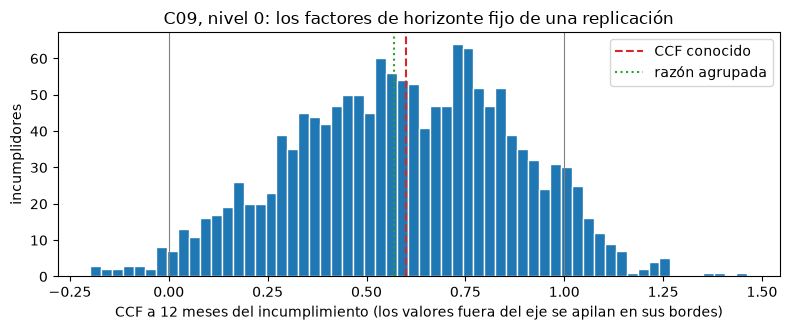

In [7]:
# Dibujar la distribución de los factores con el CCF conocido y las dos estimaciones marcadas
pooled = ccf.aggregate_ccf(obs.ccf, obs.undrawn, "pooled")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.clip(obs.ccf[defined], -0.5, 2.0), bins=60, color="tab:blue", edgecolor="white")
ax.axvline(truth, color="tab:red", linestyle="--", label="CCF conocido")
ax.axvline(pooled, color="tab:green", linestyle=":", label="razón agrupada")
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.axvline(1.0, color="grey", linewidth=0.8)
ax.set_xlabel("CCF a 12 meses del incumplimiento (los valores fuera del eje se apilan en sus bordes)")
ax.set_ylabel("incumplidores")
ax.set_title("C09, nivel 0: los factores de horizonte fijo de una replicación")
ax.legend()
fig.tight_layout()
plt.show()

El grueso de los factores se ubica entre 0 y 1 y se centra cerca del 0,6 conocido, como debe ser, pero el histograma tiene dos rasgos que un solo resumen oculta: una masa visible en 1 y más allá, las líneas que giraron todo su monto no utilizado o terminaron sobre el límite, y una cola delgada bajo 0, las líneas cuyo saldo bajó. La razón agrupada, dibujada como la línea punteada, queda a la izquierda de la verdad porque da peso a la moneda no utilizada, y las líneas con mucho monto no utilizado giran proporcionalmente menos. Ninguno de los dos resúmenes es incorrecto; responden dos preguntas distintas, y por eso un validador pide la agregación junto con el factor.

### Paso 5: cuando el monto no utilizado es pequeño

Si una línea tiene solo unas pocas unidades monetarias sin utilizar en la fecha de referencia, la razón $(EAD - E)/(L - E)$ divide por casi nada y es inestable. Qi (2009) cambia a otra razón bajo un umbral de monto no utilizado; `small_undrawn_rule(drawn, limit, ead, threshold)` devuelve qué facilidades se cambian y la razón a usar: $EAD/L$ donde se cambia, el factor europeo en el resto. El umbral es un parámetro en la moneda de los montos. La celda siguiente la aplica primero a tres facilidades inventadas, dos de ellas con menos de 50 sin utilizar, y luego a los incumplidores de la replicación del paso 4 con un umbral de 50 USD, e imprime si los factores versionados del artefacto aplican la regla.

In [8]:
# Aplicar la regla de monto pequeño a tres facilidades inventadas y a los incumplidores de la cartera generada
d = np.array([4_980.0, 4_000.0, 1_000.0])
lim = np.array([5_000.0, 4_030.0, 5_000.0])
e = np.array([5_020.0, 4_100.0, 3_000.0])
switched, ratio = ccf.small_undrawn_rule(d, lim, e, threshold=50.0)
for i in range(3):
    print(f"facilidad {i + 1}: sin utilizar {lim[i] - d[i]:7.1f}"
          f" cambiada {bool(switched[i])!s:5s} razón usada {ratio[i]:.4f}")

flag, _ = ccf.small_undrawn_rule(obs.drawn_ref[defined], obs.limit_ref[defined], obs.ead[defined], threshold=50.0)
print(f"incumplidores generados cambiados a 50 USD: {flag.sum():,} de {defined.sum():,}")
small = out["small_undrawn"]
print(f"artefacto: regla aplicada a los factores versionados: {small['applied']}")

facilidad 1: sin utilizar    20.0 cambiada True  razón usada 1.0040
facilidad 2: sin utilizar    30.0 cambiada True  razón usada 1.0174
facilidad 3: sin utilizar  4000.0 cambiada False razón usada 0.5000
incumplidores generados cambiados a 50 USD: 19 de 1,503
artefacto: regla aplicada a los factores versionados: False


## Resultados

**Respuesta:** La línea parcialmente girada del ejemplo tiene un factor europeo de 0,6250, una razón al saldo de 1,4167 y una razón al límite de 0,8500, de modo que un documento que dice «el CCF» sin nombrar el denominador puede referirse a cualquiera de los tres. En una cartera generada cuyo factor verdadero es 0,6000, el factor europeo a 12 meses promedia 0,5932 sobre 1.503 incumplidores (un sesgo de -0,0068) y agrupa 0,5704 (-0,0296); la fecha de referencia sola mueve una línea inventada de 0,7500 a 0,6757, y el tratamiento de los valores extremos mueve ocho factores inventados desde una media de 0,5929 a 0,5700 (censurados) o 0,5500 (recortados).

- **Una facilidad, tres números.** La línea parcialmente girada (saldo 60, límite 100, EAD 85) tiene un factor europeo de 0,6250, una razón al saldo de 1,4167 y una razón al límite de 0,8500. La línea totalmente girada tiene una razón al saldo de 5,0000 y la línea sobre su límite un factor europeo de 3,0000. `ead_from_ccf` devuelve las tres EAD inventadas (85, 100 y 120) desde los factores europeos, de modo que la identidad corre en ambos sentidos.
- **La fecha de referencia es un diseño.** Para la línea 1 el factor de horizonte fijo es 0,7500, el de inicio de cohorte 0,6757 y el de horizonte variable 0,6378 como media y 0,6632 agrupado. Para la línea 2, los meses en que el saldo había llegado al límite dan un factor faltante, no un 0 ni un 1.
- **Tratar un factor fuera de [0, 1] cambia la media.** Sobre ocho factores inventados, conservar todos da 0,5929, censurar da 0,5700 (descarta tres observaciones: la bajo 0, la sobre 1 y la faltante) y recortar a [0, 1], o la escala acotada, da 0,5500.
- **Una cartera generada tiene factores fuera de [0, 1] y un centro conocido.** De 1.894 incumplidores, 1.503 tienen un factor definido a 12 meses; 24 (1,60%) están bajo 0 y 102 (6,79%) sobre 1, en torno a un CCF conocido de 0,6000. La media de los factores lo yerra por -0,0068 y la razón agrupada por -0,0296.
- **La regla de monto pequeño es un interruptor.** Con un umbral de 50 USD pasa 19 de los 1.503 incumplidores generados a la razón al límite, y los factores versionados del artefacto no la aplican.

Lo que el notebook no hace: no dice qué convención debe usar un regulador o un banco, solo qué significa cada una. Las tres facilidades inventadas y las dos trayectorias existen para mostrar la aritmética y no informan sobre ningún prestamista, y la cartera generada es una replicación, de modo que sus sesgos son un sorteo y no el promedio de veinte que informa el notebook 05. El notebook siguiente vuelve a la LGD y ajusta la escalera de modelos sobre las cohortes de C08.

## Resumen

- El factor europeo es $(EAD - E)/(L - E)$, la parte del monto no utilizado usada al incumplir; Qi (2009) usa "CCF" para $EAD/E$ y "EADF" para $EAD/L$. `to_us_terms` devuelve los tres para que una página nunca los mezcle.
- La fecha de referencia es un diseño: `reference_indices` da los meses de los diseños de horizonte fijo, cohorte y horizonte variable, y `ccf_observations` devuelve un factor y un monto no utilizado en cada uno.
- Un factor no está definido (un valor faltante, nunca 0 o 1) cuando la línea está totalmente usada o sobre su límite en la fecha de referencia.
- Un factor fuera de [0, 1] es real; `treat_ccf` lo conserva, censura, recorta o acota, e informa los conteos.
- C09 es un generador con un CCF conocido, así que cada estimación de los notebooks siguientes se juzga contra la verdad. La regla del monto no utilizado pequeño es un cambio parametrizado que los factores horneados no aplican.

**Qué probar a continuación.** Cambia el mes de incumplimiento o la trayectoria del paso 2 y mira cómo se mueve el factor con el diseño; luego sigue con el notebook 03, la escalera de modelos de LGD ajustados sobre las cohortes de C08.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los factores de conversión supervisores y el piso de EAD se aplican en el notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2: las razones al saldo y al límite, y el cambio bajo un monto no utilizado pequeño, como los nombra la documentación del motor de `riskvalidation.lgd_ead.ccf`.
- Moral, G. (2006), los tres diseños de fecha de referencia, como los resume la investigación de este producto y el docstring de `reference_indices` (el capítulo no se leyó: detalle NO VERIFICADO).
- Este repositorio: `docs/design/SDD.md` (caso C09, un generador con verdad conocida) y `data/derived/C09/level-0.json`.